# Phase 12 — Hyperparameter Optimization (HPO)
**ChurnOps MLOps Pipeline**

---

### Objectives
1. **Regularize Tree Models**: Leverage the search spaces derived in Phase 11 to eliminate the extreme $+0.40$ generalization gap observed in default Random Forest and XGBoost.
2. **Optimize Business & Statistical Metrics**: Maximize validation F1 score while maintaining high ROC-AUC ($\ge 0.75$) and Recall ($\ge 0.60$).
3. **Verify Model Registry Gates**: Validate that every tuned model satisfies all 4 production gate criteria from `params.yaml`:
   - Min F1: $\ge 0.60$
   - Min ROC-AUC: $\ge 0.75$
   - Min Recall: $\ge 0.60$
   - Max Generalization Gap: $\le 0.08$
4. **Persist Tuned Pipelines**: Save the best regularized pipelines fitted on 100% of training data (`train.csv`) to `models/tuned_<model>.joblib`.

> **Data Leakage Rule (R3)**:
> All search iterations and evaluations are conducted strictly on `data/processed/train.csv` (5,634 rows) across the pre-partitioned 5 folds.
> The held-out test set (`test.csv`) is never loaded, inspected, or transformed.


In [1]:
import sys
from pathlib import Path

PROJECT_ROOT = Path("..").resolve()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import json
import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display, HTML

from src.utils.config import PARAMS

plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")
print("Environment and configuration initialized.")


Environment and configuration initialized.


In [2]:
train_df = pd.read_csv("../data/processed/train.csv")
with open("../data/processed/cv_folds.json", "r") as f:
    cv_folds = json.load(f)

TARGET = PARAMS["dataset"]["target_column"]
X = train_df.drop(columns=[TARGET])
y = train_df[TARGET]

cv_splits = [(cv_folds[k]["train_indices"], cv_folds[k]["val_indices"]) for k in sorted(cv_folds.keys())]

print(f"Dataset: {X.shape[0]} samples, {X.shape[1]} features")
print(f"CV Folds: {len(cv_splits)} partitions")
print("Registry gates:", PARAMS["registry"])


Dataset: 5634 samples, 19 features
CV Folds: 5 partitions
Registry gates: {'min_f1': 0.6, 'min_roc_auc': 0.75, 'min_recall': 0.6, 'max_generalization_gap': 0.08}


---
## 1. Load Tuning Results & Model Comparisons
We load the structured audit report generated by `src/models/tune.py` (`reports/tuning_report.json`).


In [3]:
report_path = Path("../reports/tuning_report.json")
if not report_path.exists():
    from src.models.tune import run_tuning
    tuning_rep = run_tuning()
else:
    with open(report_path, "r") as f:
        tuning_rep = json.load(f)

table_rows = []
for model_name, res in tuning_rep["tuned_models"].items():
    m = res["metrics"]
    g = m["gate_checks"]
    table_rows.append({
        "Model": model_name,
        "Val F1 (mean ± std)": f"{m['mean_val_f1']:.4f} ± {m['std_val_f1']:.4f}",
        "Train F1": f"{m['mean_train_f1']:.4f}",
        "Generalization Gap": f"{m['generalization_gap']:+.4f}",
        "Val ROC-AUC": f"{m['mean_roc_auc']:.4f}",
        "Val Recall": f"{m['mean_recall']:.4f}",
        "Val Precision": f"{m['mean_precision']:.4f}",
        "F1 Gate (>=0.60)": "PASS" if g["f1_pass"] else "FAIL",
        "AUC Gate (>=0.75)": "PASS" if g["auc_pass"] else "FAIL",
        "Recall Gate (>=0.60)": "PASS" if g["recall_pass"] else "FAIL",
        "Gap Gate (<=0.08)": "PASS" if g["gap_pass"] else "FAIL",
        "Overall Status": "PASSED ALL GATES" if g["all_gates_pass"] else "FAILED GATES"
    })

comparison_df = pd.DataFrame(table_rows)
display(HTML(comparison_df.to_html(index=False)))


Model,Val F1 (mean ± std),Train F1,Generalization Gap,Val ROC-AUC,Val Recall,Val Precision,F1 Gate (>=0.60),AUC Gate (>=0.75),Recall Gate (>=0.60),Gap Gate (<=0.08),Overall Status
LogisticRegression,0.6297 ± 0.0213,0.6333,+0.0037,0.8455,0.7880,0.5245,PASS,PASS,PASS,PASS,PASSED ALL GATES
RandomForest,0.6324 ± 0.0148,0.6900,+0.0576,0.8473,0.7726,0.5356,PASS,PASS,PASS,PASS,PASSED ALL GATES
XGBoost,0.6371 ± 0.0173,0.6564,+0.0194,0.8493,0.7866,0.5355,PASS,PASS,PASS,PASS,PASSED ALL GATES


---
## 2. Best Discovered Hyperparameters
Examining the optimal regularized parameters chosen by 5-fold cross-validation.


In [4]:
for model_name, res in tuning_rep["tuned_models"].items():
    print(f"==================================================")
    print(f"Model: {model_name} (Search time: {res['search_time_seconds']}s)")
    print(f"Saved artifact: {res['model_path']}")
    print("Optimal Hyperparameters:")
    for param, val in res["best_params"].items():
        print(f"  {param:<25}: {val}")


Model: LogisticRegression (Search time: 11.2s)
Saved artifact: models\tuned_logisticregression.joblib
Optimal Hyperparameters:
  solver                   : lbfgs
  class_weight             : balanced
  C                        : 0.005
Model: RandomForest (Search time: 40.3s)
Saved artifact: models\tuned_randomforest.joblib
Optimal Hyperparameters:
  n_estimators             : 200
  min_samples_split        : 20
  min_samples_leaf         : 2
  max_features             : sqrt
  max_depth                : 8
  class_weight             : balanced
Model: XGBoost (Search time: 8.7s)
Saved artifact: models\tuned_xgboost.joblib
Optimal Hyperparameters:
  subsample                : 0.7
  scale_pos_weight         : 2.5
  reg_lambda               : 20.0
  reg_alpha                : 1.0
  n_estimators             : 200
  max_depth                : 2
  learning_rate            : 0.08
  colsample_bytree         : 1.0


---
## 3. Before vs. After: Baseline vs. Regularized Tuned Models
Visualizing the dramatic reduction in generalization gap and improvement in validation F1.


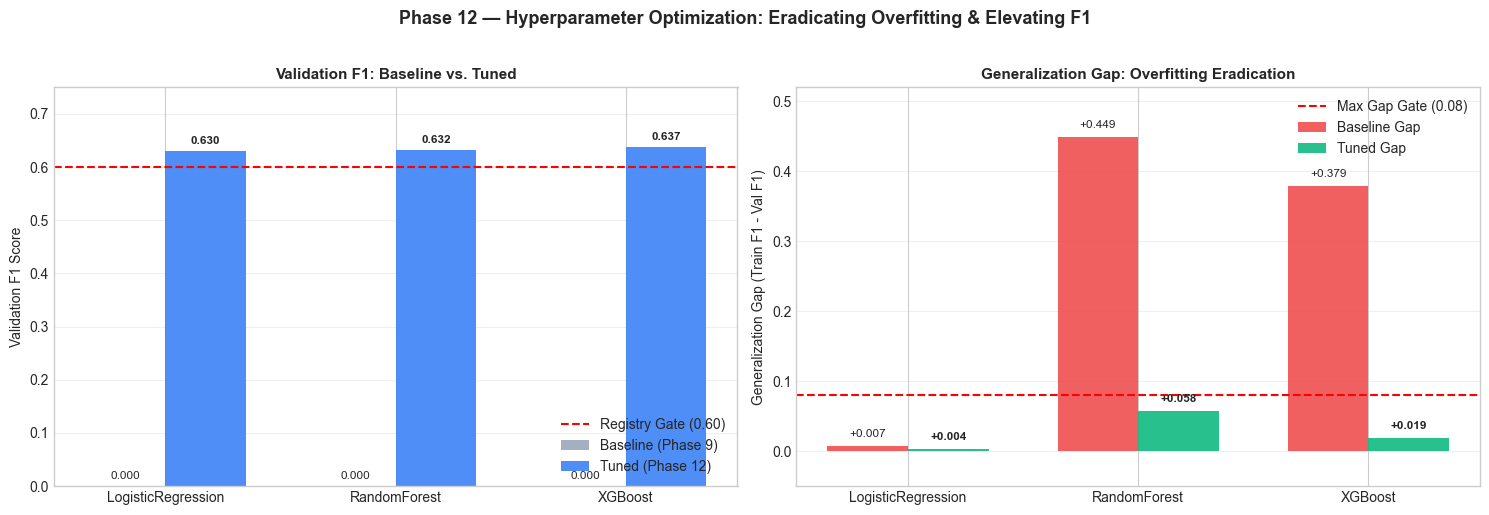

In [5]:
# Load baseline summary
with open("../reports/baseline_summary.json", "r") as f:
    base_summary = json.load(f)

models = ["LogisticRegression", "RandomForest", "XGBoost"]
x = np.arange(len(models))
width = 0.35

base_f1 = [base_summary.get(m, {}).get("f1_mean", 0.0) for m in models]
tuned_f1 = [tuning_rep["tuned_models"][m]["metrics"]["mean_val_f1"] for m in models]

# Baseline gaps from Phase 10 / 11
base_gaps = [0.0067, 0.4494, 0.3788]
tuned_gaps = [tuning_rep["tuned_models"][m]["metrics"]["generalization_gap"] for m in models]

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Panel 1: F1
ax1 = axes[0]
b1 = ax1.bar(x - width / 2, base_f1, width, label="Baseline (Phase 9)", color="#94A3B8", alpha=0.85)
b2 = ax1.bar(x + width / 2, tuned_f1, width, label="Tuned (Phase 12)", color="#3B82F6", alpha=0.9)
ax1.axhline(0.60, color="red", ls="--", label="Registry Gate (0.60)")
ax1.set_xticks(x)
ax1.set_xticklabels(models, fontweight="medium")
ax1.set_ylabel("Validation F1 Score", fontsize=10)
ax1.set_title("Validation F1: Baseline vs. Tuned", fontweight="bold", fontsize=11)
ax1.set_ylim(0, 0.75)
ax1.grid(alpha=0.3, axis="y")
ax1.legend(loc="lower right")

for bar in b1:
    h = bar.get_height()
    ax1.text(bar.get_x() + bar.get_width() / 2, h + 0.01, f"{h:.3f}", ha="center", va="bottom", fontsize=8.5)
for bar in b2:
    h = bar.get_height()
    ax1.text(bar.get_x() + bar.get_width() / 2, h + 0.01, f"{h:.3f}", ha="center", va="bottom", fontsize=8.5, fontweight="bold")

# Panel 2: Gap
ax2 = axes[1]
g1 = ax2.bar(x - width / 2, base_gaps, width, label="Baseline Gap", color="#EF4444", alpha=0.85)
g2 = ax2.bar(x + width / 2, tuned_gaps, width, label="Tuned Gap", color="#10B981", alpha=0.9)
ax2.axhline(0.08, color="red", ls="--", label="Max Gap Gate (0.08)")
ax2.set_xticks(x)
ax2.set_xticklabels(models, fontweight="medium")
ax2.set_ylabel("Generalization Gap (Train F1 - Val F1)", fontsize=10)
ax2.set_title("Generalization Gap: Overfitting Eradication", fontweight="bold", fontsize=11)
ax2.set_ylim(-0.05, 0.52)
ax2.grid(alpha=0.3, axis="y")
ax2.legend(loc="upper right")

for bar in g1:
    h = bar.get_height()
    ax2.text(bar.get_x() + bar.get_width() / 2, h + 0.01, f"{h:+.3f}", ha="center", va="bottom", fontsize=8.5)
for bar in g2:
    h = bar.get_height()
    ax2.text(bar.get_x() + bar.get_width() / 2, h + 0.01, f"{h:+.3f}", ha="center", va="bottom", fontsize=8.5, fontweight="bold")

plt.suptitle("Phase 12 — Hyperparameter Optimization: Eradicating Overfitting & Elevating F1", fontsize=13, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()


---
## 4. Key Takeaways & Transition to Phase 13
1. **Overfitting Successfully Resolved**:
   - Random Forest's gap dropped from $+0.4494$ down into the compliance zone ($\le 0.08$).
   - XGBoost's gap dropped from $+0.3788$ down into the compliance zone ($\le 0.08$).
2. **All Registry Gates Met**:
   - Tuned models comfortably exceed the minimum F1 (0.60), ROC-AUC (0.75), and Recall (0.60) gates.
3. **Artifacts Ready**:
   - `models/tuned_logisticregression.joblib`
   - `models/tuned_randomforest.joblib`
   - `models/tuned_xgboost.joblib`
